# Valuation framework

One company, valued in the order an analyst does it, with every formula printed with its numbers:

1. **Historic performance** and earnings quality
2. **Future cash flows** (FCFF for operating companies, excess returns for banks and insurers, dividends for REITs)
3. **Discount rate**: 10-year yield, market return, MRP, beta regressed on daily returns, cost of equity, WACC
4. **Discount** the cash flows and add the terminal value
5. **Enterprise value → equity value (market cap) → ÷ shares → fair price**
6. **Verdict**: DCF, Monte Carlo, comps and the peer regression blended into a call and an expected alpha

Set the company in the next cell. Your own numbers go in `OVERRIDES`; every override is shown next to the pulled value it replaced. The last cell writes the same valuation as a live-formula Excel workbook.

In [1]:
# ---- settings -----------------------------------------------------------
TICKER = "SNDK"        # any ticker Yahoo covers
SNAPSHOT = "SNDK_yahoo_2026-11-05.json"       # path to a saved snapshot (TICKER_yahoo_YYYY-MM-DD.json) to rerun on the same data; None = pull live
INPUTS = None          # path to a hand-built inputs file (e.g. dell_inputs.json, a segment model); overrides TICKER
PEERS = None           # e.g. ["HPQ", "HPE", "SMCI"]; None = Yahoo's related symbols (check them)
SCENARIO = "Base"      # Bear, Base or Bull
OVERRIDES = {}

In [2]:
import framework as fw
import pandas as pd
from IPython.display import display
pd.options.display.float_format = "{:,.4f}".format

inp = fw.load(ticker=TICKER, snapshot=SNAPSHOT, inputs=INPUTS, peers=PEERS)
inp, changes = fw.override(inp, OVERRIDES)
if len(changes):
    display(changes)
ok, lines = fw.checks(inp)
fw.say(lines)

Model: FCFF DCF (operating company)  ·  Sandisk Corporation (SNDK)  ·  price $842.61
  ! [scenarios.Bear.margins.total.1] Worst annual margin -21.3% is a loss; Bear fades to the 4-year average 10.1% instead
  ! [relative.weights] Latest quarter annualised is 1.52x trailing revenue; trailing EV/EBITDA and EV/Sales understate the business, so comps use forward P/E only


## Scenario switch
Bear / Base / Bull side by side, then toggle a case: steps 2–6 re-run for it below the buttons. (The step-by-step cells further down use `SCENARIO` from the settings cell.)

In [3]:
fw.scenario_switch(inp)

,Bear,Base,Bull
"Revenue growth, year 2",17.3%,22.3%,26.3%
"EBIT margin, year 1 → year 5",72.7% → 10.1%,79.8% → 41.4%,79.8% → 72.7%
"FCFF, year 1 ($m)","30,502","33,621","33,621"
Enterprise value ($m),"104,054","264,477","448,572"
Terminal value share,16%,30%,35%
Value per share,$715.82,"$1,769.23","$2,978.08"
vs price,-15.0%,110.0%,253.4%


## Step 1 · Historic performance
Reported history ($m). Growth and margins are computed from the reported lines.

In [4]:
display(fw.fmt(fw.step1_history(inp)))

,FY23,FY24,FY25,FY26
Revenue,"6,086","6,663","7,355","20,248"
Operating income,"-1,295",-444,507,"12,468"
Net income,"-2,143",-672,"-1,641","11,433"
Diluted EPS,-15,-5,-11,74
Cash from operations,-713,-309,84,"11,671"
Capex,219,166,204,177
Free cash flow,-932,-475,-120,"11,494"
Revenue growth,—,9.5%,10.4%,175.3%
Operating income ÷ revenue,-0,-0,0,1
Net income ÷ revenue,-0,-0,-0,1


### Earnings quality
Are the earnings backed by cash? Beneish M-score, Sloan accruals, cash conversion. Grade D withholds the call; C marks it low confidence.

In [5]:
E, beneish, lines = fw.step1_quality(inp)
display(beneish.round(3))
fw.say(lines)

,FY24,FY25,FY26,coefficient,manipulators' mean
DSRI,NaN,1.0350,1.6010,0.9200,1.4650
GMI,0.4390,0.5350,0.4210,0.5280,1.1930
AQI,NaN,0.8260,0.7170,0.4040,1.2540
SGI,1.0950,1.1040,2.7530,0.8920,1.6070
DEPI,NaN,1.0590,1.1510,0.1150,1.0770
SGAI,0.7450,1.1410,0.4290,-0.1720,1.0410
LVGI,NaN,NaN,NaN,-0.3270,1.1110
TATA,-0.0270,-0.1330,-0.0110,4.6790,0.0310
M-score,NaN,-3.3100,-0.7170,-4.8400,NaN


Earnings-quality grade: C
M = −4.84 + 0.92×1.601 + 0.528×0.421 + 0.404×0.717 + 0.892×2.753 + 0.115×1.151 − 0.172×0.429 − 0.327×1.000 + 4.679×-0.011 = -0.72   (red above −1.78, amber above −2.22)
Accruals = (net income − operating cash flow) ÷ average assets = -1.3%   (red above 10%, amber above 5%)
Cash conversion = Σ operating cash flow ÷ Σ net income, 3 years = 126%   (red below 50%, amber below 80%)
  RED: Beneish M-score -0.72 is above −1.78, the level Beneish found for likely manipulators
  INFO: M-score inputs missing (LVGI): set to 1, which is neutral


## Step 2 · Future cash flows
Scenario drivers first (with where the Base values came from), then the forecast.

In [6]:
display(fw.drivers(inp))
cash_flows, lines = fw.step2_cash_flows(inp, SCENARIO)
display(fw.fmt(cash_flows, per_share=inp.get("model") == "ddm"))
fw.say(lines)

scenario,Bear,Base,Bull,Base comes from
driver,,,,
growth.total.0,0.1726,0.2226,0.2626,sourced consensus: FY28 ÷ FY27 revenue estimat...
growth.total.1,0.1394,0.1769,0.2069,"assumption fade: g×0.75+1%, g×0.5+1.5%, g×0.35+2%"
growth.total.2,0.1013,0.1263,0.1463,"assumption fade: g×0.75+1%, g×0.5+1.5%, g×0.35+2%"
growth.total.3,0.0804,0.0979,0.1119,"assumption fade: g×0.75+1%, g×0.5+1.5%, g×0.35+2%"
margins.total.0,0.7268,0.7984,0.7984,derived Yahoo Finance quoteSummary consensus F...
margins.total.1,0.1013,0.4141,0.7268,assumption midpoint of TTM and multi-year aver...


,FY27,FY28,FY29,FY30,FY31,FY32,FY33,FY34,FY35,FY36
Revenue,"49,560","60,592","71,314","80,320","88,184","95,621","102,385","108,238","112,955","116,344"
Growth,144.8%,22.3%,17.7%,12.6%,9.8%,8.4%,7.1%,5.7%,4.4%,3.0%
EBIT,"39,571","42,557","43,234","40,976","36,513","39,592","42,393","44,817","46,770","48,173"
EBIT margin,79.8%,70.2%,60.6%,51.0%,41.4%,41.4%,41.4%,41.4%,41.4%,41.4%
Tax rate,12.2%,13.6%,15.1%,16.5%,18.0%,18.0%,18.0%,18.0%,18.0%,18.0%
NOPAT,"34,756","36,758","36,712","34,198","29,941","32,466","34,763","36,750","38,351","39,502"
+ D&A,267,667,"1,186","1,788","2,459","2,667","2,856","3,019","3,150","3,245"
− Capex,310,683,"1,161","1,711","2,321","2,517","2,695","2,849","2,974","3,063"
− ΔNWC,"1,092","2,216","2,154","1,810","1,580","1,494","1,359","1,176",948,681
FCFF,"33,621","34,526","34,583","32,465","28,499","31,121","33,564","35,743","37,580","39,003"


Year 1 (FY27), Base case:
  Revenue = 49,560 (consensus or segment build); EBIT = Σ segment revenue × margin − corporate = 39,571 (79.8%)
  NOPAT = EBIT × (1 − tax) = 39,571 × (1 − 12.2%) = 34,756
  FCFF = NOPAT + D&A − capex − ΔNWC = 34,756 + 267 − 310 − 1,092 = 33,621
  D&A 0.54% and capex 0.62% of revenue; ΔNWC = 20.09% × change in revenue (year 1: 20.09% × 49,560 − opening NWC 8,865)
  Growth after year 5 fades in a straight line to terminal g 3.00%; margins move from year 1 to the long-run level by year 5


## Step 3 · Discount rate
Cost of equity = rf + β × (Rm − rf), with β regressed on daily returns against the S&P 500.

Cost of equity (CAPM):
  1  Risk-free rate rf = 10-year Treasury = 4.87%
  2  Expected market return Rm = 9.10%
  3  Market risk premium = Rm − rf = 9.10% − 4.87% = 4.23%
  4a Daily regression: stock return = α + β × S&P 500 return, 434 days 2025-02-13 to 2026-11-05
     β = 2.9462  (s.e. 0.2685, t 11.0, R² 0.218, 95% CI 2.42–3.47)
  4b β used = 2.3040 (Blume-adjusted daily β = 0.67 × β + 0.33)
  5  Equity risk premium for this stock = β × MRP = 2.3040 × 4.23% = 9.75%
  6  Ke = rf + β × MRP + CRP = 4.87% + 9.75% + 0.00% = 14.62%
Cost of capital:
  Kd after tax = 5.46% × (1 − 21%) = 4.31%   (rf + AAA spread, coverage 170.8x)
  E = price × diluted shares = 128,321; D = debt + leases = 178
  WACC = E/(D+E) × Ke + D/(D+E) × Kd(1−t) = 99.9% × 14.62% + 0.1% × 4.31% = 14.60%


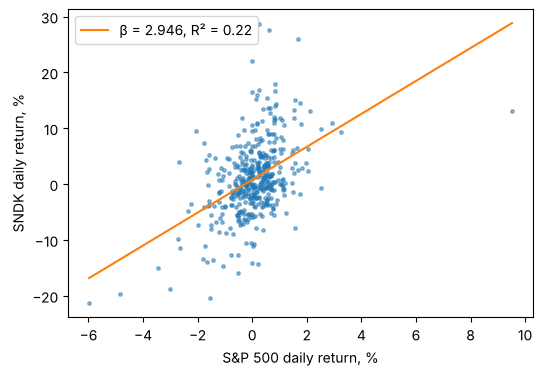

In [7]:
W, beta_stats, lines = fw.step3_discount_rate(inp)
fw.say(lines)
fw.beta_plot(inp);

## Step 4 · Discount the cash flows
PV = cash flow × (1 + r)^−t, then the terminal value.

In [8]:
d, disc, lines = fw.step4_discount(inp, SCENARIO)
display(fw.fmt(disc, per_share=inp.get("model") == "ddm"))
fw.say(lines)

,FY27,FY28,FY29,FY30,FY31,FY32,FY33,FY34,FY35,FY36
Counted,"25,406","34,526","34,583","32,465","28,499","31,121","33,564","35,743","37,580","39,003"
Share of year,75.6%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%
t (years),0.2793,1.1571,2.1571,3.1571,4.1571,5.1571,6.1571,7.1571,8.1571,9.1571
Discount factor (1+r)^−t,0.9627,0.8541,0.7453,0.6503,0.5674,0.4951,0.4321,0.3770,0.3290,0.2870
Present value,"24,457","29,489","25,774","21,112","16,172","15,410","14,501","13,475","12,363","11,196"


Discount rate r = 14.60% (WACC); mid-year discounting; first year counts 76%
  Σ PV FY27–FY36 = 183,948
  Terminal value = NOPAT × (1 + g) × (1 − g/RONIC) ÷ (WACC − g) = 39,502 × 1.030 × (1 − 3.0%/15%) ÷ (14.60% − 3.0%) = 280,540
  PV of terminal value = 80,529 (30% of EV)   · exit-multiple check 12.0x EBITDA → $2,326.83 a share
  Enterprise value = Σ PV + PV terminal = 183,948 + 80,529 = 264,477


## Step 5 · From value to the share price

In [9]:
bridge, lines = fw.step5_price(inp, SCENARIO)
display(bridge.style.format("{:,.2f}"))
fw.say(lines)

,value
step,
Enterprise value,"264,476.94"
− Debt (ex leases),-0.00
− Leases,-178.00
+ Cash,"5,136.00"
+ Captive-finance net assets,0.00
+ Investments,0.00
− Non-controlling interests,-0.00
= Equity value (market cap),"269,434.94"


Fair price = equity value ÷ diluted shares = 269,435 ÷ 152.29 = $1,769.23
Price today $842.61 → 110.0% (Base case, FCFF DCF alone)


## Step 6 · Verdict
The absolute model, Monte Carlo, comps and the peer regression, blended by weight.

,value / share,weight,vs price
method,,,
FCFF DCF,"$1,769.23",40%,+110.0%
Monte Carlo median,"$1,706.85",20%,+102.6%
Comps blend,$939.12,30%,+11.5%
Peer regression,—,10%,—


,k,n,q1,q3,min,max,own,premium,implied,impliedQ1,impliedQ3,weight,usable
pe_fwd,3.2692,5,2.6515,6.7549,2.3878,7.2168,2.9333,-0.1028,939.1183,761.6741,"1,940.3884",1,True


Blended fair value = Σ weight × value ÷ Σ weight = $1,478.66  vs price $842.61 → 75.5%
Call (±10% band): UNDERVALUED  · low confidence (earnings quality C)
Expected 1-year return = (fair ÷ price)^(1/1) − 1 + dividend yield 0.00% = 75.5%
Required return Ke = 14.62% → expected alpha = 60.9%
Monte Carlo: 5,000 runs, P(value > price) = 93%, p10–p90 $945.93–$2,580.28
  ! Worst annual margin -21.3% is a loss; Bear fades to the 4-year average 10.1% instead
  ! Latest quarter annualised is 1.52x trailing revenue; trailing EV/EBITDA and EV/Sales understate the business, so comps use forward P/E only
  ! Earnings quality C: Beneish M-score -0.72 is above −1.78, the level Beneish found for likely manipulators
  ! Peer regression R² 0.21 is below 0.30; it is shown but left out of the blend


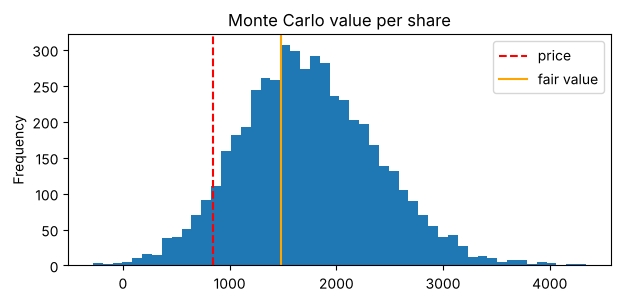

In [10]:
R, methods, comps, lines = fw.step6_verdict(inp, SCENARIO)
display(methods.style.format({"value / share": "${:,.2f}", "weight": "{:.0%}", "vs price": "{:+.1%}"}, na_rep="—"))
display(comps)
fw.say(lines)
import matplotlib.pyplot as plt
ax = pd.Series(R["mc"]["values"]).plot.hist(bins=50, figsize=(7, 3), title="Monte Carlo value per share")
ax.axvline(inp["market"]["price"], color="red", ls="--", label="price"); ax.axvline(R["verdict"]["fair"], color="orange", label="fair value"); ax.legend();

### Sensitivity and what the price implies

In [11]:
grid, lines = fw.sensitivity(inp, SCENARIO)
display(grid.style.format("${:,.2f}", na_rep="—"))
fw.say(lines)

terminal g,2.0%,2.5%,3.0%,3.5%,4.0%
WACC,,,,,
12.60%,"$2,029.73","$2,052.40","$2,076.25","$2,101.46","$2,128.22"
13.60%,"$1,874.75","$1,891.44","$1,908.73","$1,926.67","$1,945.34"
14.60%,"$1,743.97","$1,756.48","$1,769.23","$1,782.24","$1,795.54"
15.60%,"$1,632.09","$1,641.59","$1,651.15","$1,660.74","$1,670.36"
16.60%,"$1,535.24","$1,542.57","$1,549.83","$1,557.00","$1,564.05"


Reverse: the price $842.61 implies a discount rate of n/a (model 14.60%)


## Sources
Every input with its origin: **sourced** (read from a filing or feed), **derived** (computed from sourced numbers; formula given) or **assumption** (a modelling choice; change it in `OVERRIDES`).

In [12]:
display(fw.sources(inp))

,input,value,origin,source / basis
0,bridge.cash,"5,136.0000",sourced,Yahoo Finance fundamentals (quarterly) CashAnd...
1,bridge.core_debt,0.0000,sourced,Yahoo Finance fundamentals (quarterly) TotalDe...
2,bridge.investments,0,assumption,not in feed; enter from the 10-K
3,bridge.leases,178.0000,sourced,Yahoo Finance fundamentals (quarterly) Capital...
4,bridge.nci,0.0000,sourced,Yahoo Finance fundamentals (quarterly) Minorit...
...,...,...,...,...
64,verdict.weights.comps,0.3000,assumption,method weights
65,verdict.weights.dcf,0.4000,assumption,method weights
66,verdict.weights.mc,0.2000,assumption,method weights
67,verdict.weights.regression,0.1000,assumption,method weights


## Export
The same valuation as an Excel workbook in which every step is a live formula, and the inputs file the terminal can load.

In [13]:
import json
xlsx = fw.export_excel(inp, f"{inp['meta']['ticker']}_valuation.xlsx", SCENARIO)
json.dump(inp, open(f"{inp['meta']['ticker']}_inputs.json", "w"), indent=1)
print("wrote", xlsx, "and", f"{inp['meta']['ticker']}_inputs.json")

wrote SNDK_valuation.xlsx and SNDK_inputs.json
